# 12 – Ensemble of E3 (Elia) and V4 (Fatemeh)

**Question:** does averaging the predictions of our two best models beat the best single one?

| model | augmentation | OOF clean | OOF shifted | Kaggle public |
|---|---|---|---|---|
| **E3** `e3_hue_blur` (notebook 11) | dihedral + hue rotation + mild blur | 0.847 | 0.846 | 0.8574 |
| **V4** Fatemeh, shared split | free rotation, zoom, shift, strong colour, strong blur, lines/patches, class weights, 25 epochs | 0.859 | 0.851 | 0.8678 |

Both models use the **same 2,995 images and the same 5 folds**. Every image therefore has an out-of-fold (OOF) prediction from both models, made by models that never saw it, and the ensemble can be evaluated **without training anything**: we only average probabilities that are already saved.

**Why it can help.** An ensemble gains when the models make **different** mistakes: where one is wrong and the other is right and confident, the average can fix the prediction. E3 and V4 are trained with very different augmentations, so their mistakes should differ more than E3's and E4's.

**How:** for each image, `p = w · p_V4 + (1 − w) · p_E3` (probabilities of the 10 classes), then the predicted class is the one with the highest `p`.
- The main candidate is **w = 0.5** (plain average).
- We also look at the whole curve w = 0 … 1, but choosing w on the OOF slightly overfits it. We move away from 0.5 only if another weight is clearly better (≳ 0.005).

**Nothing is trained here:** the notebook runs on the CPU in seconds.

**Inputs needed** (the V4 files come from the *Output* tab of Fatemeh's Kaggle notebook version, the one that scored 0.8678). Put these 5 files in `families/elia/outputs/v4_fatemeh/`:
- `oof_clean.npy`
- `oof_shifted.npy`
- `oof_ids.csv`
- `test_probs.npy`
- `submission.csv`

The E3 files are already in `outputs/e3_hue_blur/` (from notebook 11).

## 0. Setup and loading

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score

import train_lib as T
import common as C

plt.rcParams["figure.dpi"] = 80
E3, V4, ENS = "e3_hue_blur", "v4_fatemeh", "ensemble_e3_v4"
OUT = T.OUT_DIR
K = C.N_CLASSES
P_COLS = lambda name: [f"p{c}_{name}" for c in range(K)]

# --- E3 (notebook 11): oof.csv with id, label, fold, p0_clean.., p0_shifted..; test_probs (folds, N, 10) ---
e3 = pd.read_csv(OUT / E3 / "oof.csv", dtype={"id": str})
e3_test = np.load(OUT / E3 / "test_probs.npy")
e3_test = e3_test.mean(0) if e3_test.ndim == 3 else e3_test          # mean of the 5 fold models

# --- V4 (Fatemeh, Kaggle): oof_clean / oof_shifted (2995, 10) in the row order of oof_ids.csv; test_probs (N, 10) ---
v4_dir = OUT / V4
v4_ids = pd.read_csv(v4_dir / "oof_ids.csv", dtype={"id": str})
v4_clean, v4_shift = np.load(v4_dir / "oof_clean.npy"), np.load(v4_dir / "oof_shifted.npy")
v4_test = np.load(v4_dir / "test_probs.npy")
v4_sub = pd.read_csv(v4_dir / "submission.csv", dtype={"id": str})

test_ids = pd.read_csv(C.DATA / "sample_submission.csv", dtype={"id": str}).id.tolist()
print("E3 OOF", e3.shape, "| E3 test", e3_test.shape)
print("V4 OOF", v4_clean.shape, v4_shift.shape, "| V4 test", v4_test.shape)

E3 OOF (2995, 23) | E3 test (14736, 10)
V4 OOF (2995, 10) (2995, 10) | V4 test (14736, 10)


## 1. Sanity checks

Before averaging, we check that the two models talk about the **same images in the same order**: same ids, same labels and same folds in the OOF, and the same test order. We also recompute each model's scores to verify that we are reading the right files:
- **E3:** 0.8467 clean / 0.8458 shifted;
- **V4:** 0.8587 clean / 0.8513 shifted.

The V4 rows are re-ordered to E3's order through the ids, so the two do not need to be saved in the same order.

In [2]:
# OOF: align V4 to E3's row order through the ids
pos = pd.Series(np.arange(len(v4_ids)), index=v4_ids.id)
assert set(v4_ids.id) == set(e3.id) and len(v4_ids) == len(e3) == 2995, "the two OOF files do not cover the same images"
order = pos.loc[e3.id].to_numpy()
v4_ids, v4_clean, v4_shift = v4_ids.iloc[order].reset_index(drop=True), v4_clean[order], v4_shift[order]
assert (v4_ids.label.to_numpy() == e3.label.to_numpy()).all(), "labels differ"
assert (v4_ids.fold.to_numpy() == e3.fold.to_numpy()).all(), "folds differ: the models were not trained on the same split"
assert not np.isnan(v4_clean).any() and not np.isnan(v4_shift).any(), "V4 OOF is incomplete (QUICK run?)"

# test: same order as sample_submission
assert v4_test.shape == e3_test.shape == (len(test_ids), K)
assert v4_sub.id.tolist() == test_ids, "V4 test order differs from sample_submission"
assert (v4_sub.label.to_numpy() == v4_test.argmax(1)).all(), "V4 test_probs.npy does not match its submission.csv"

y, folds = e3.label.to_numpy(), e3.fold.to_numpy()
PROBS = {   # name -> (clean OOF, shifted OOF, test)
    "E3": (e3[P_COLS("clean")].to_numpy(), e3[P_COLS("shifted")].to_numpy(), e3_test),
    "V4": (v4_clean, v4_shift, v4_test),
}
f1w = lambda P: f1_score(y, P.argmax(1), average="weighted")
for name, (pc, ps, _) in PROBS.items():
    print(f"{name}: OOF F1 clean {f1w(pc):.4f} | shifted {f1w(ps):.4f}")

E3: OOF F1 clean 0.8467 | shifted 0.8458
V4: OOF F1 clean 0.8587 | shifted 0.8513


> **Comment: sanity checks passed.** Both files match the known runs:
> - E3 gives 0.8467 / 0.8458;
> - V4 gives 0.8587 / 0.8513, so it is exactly the run of Fatemeh's notebook.
>
> Ids, labels, folds and the test order are aligned: any mismatch would have stopped the notebook with an error.

## 2. Do the two models make different mistakes?

An ensemble can only fix an image if **at least one** model gets it right. The table splits the OOF images into four groups:
- both right;
- only E3 right;
- only V4 right;
- both wrong.

"Both wrong" is roughly the floor of the error: averaging cannot fix those images, except in rare cases where the correct class wins only on the average. The two "only one right" groups are where the ensemble can gain, if the right model is more confident than the wrong one.

In [3]:
rows = {}
for val, i in [("clean", 0), ("shifted", 1)]:
    r3 = PROBS["E3"][i].argmax(1) == y
    r4 = PROBS["V4"][i].argmax(1) == y
    rows[val] = {"both right": (r3 & r4).mean(), "only E3 right": (r3 & ~r4).mean(),
                 "only V4 right": (~r3 & r4).mean(), "both wrong": (~r3 & ~r4).mean(),
                 "same prediction": (PROBS["E3"][i].argmax(1) == PROBS["V4"][i].argmax(1)).mean()}
(pd.DataFrame(rows).T * 100).round(1).astype(str) + " %"

,both right,only E3 right,only V4 right,both wrong,same prediction
clean,82.5 %,2.5 %,3.6 %,11.4 %,92.6 %
shifted,81.9 %,3.0 %,3.5 %,11.6 %,92.0 %


> **Comment: the two models make almost the same mistakes.**
>
> | | clean | shifted |
> |---|---|---|
> | same prediction | 92.6% | 92.0% |
> | both right | 82.5% | 81.9% |
> | only E3 right | 2.5% | 3.0% |
> | only V4 right | 3.6% | 3.5% |
> | both wrong | 11.4% | 11.6% |
>
> - The ensemble can gain **only on the ~6% of images where exactly one model is right**, and it fixes those only when the right model is also the more confident one.
> - The **11.4% "both wrong"** are a floor that this ensemble cannot touch. Many of them are probably the doubtful labels (`review`) and the genuinely ambiguous disturbed/loose-spiral galaxies.
>
> Despite very different augmentations, the two models have learnt very similar things: same architecture, same data, same resolution. A small gain is therefore the most we can expect.

## 3. Ensemble weight: from E3 alone (w = 0) to V4 alone (w = 1)

For each weight `w` we average the probabilities and compute the OOF weighted F1 on both validations.

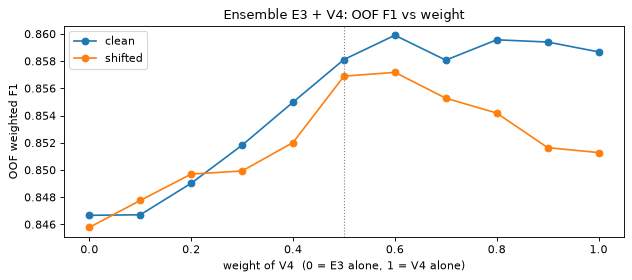

,F1 clean,F1 shifted
w (V4 weight),,
0.000000,0.8467,0.8458
0.100000,0.8467,0.8478
0.200000,0.8490,0.8497
0.300000,0.8518,0.8499
0.400000,0.8550,0.8520
0.500000,0.8581,0.8569
0.600000,0.8599,0.8572
0.700000,0.8581,0.8553
0.800000,0.8596,0.8542


In [4]:
W = np.round(np.linspace(0, 1, 11), 2)
blend = lambda w, i: w * PROBS["V4"][i] + (1 - w) * PROBS["E3"][i]
curve = pd.DataFrame({"w (V4 weight)": W,
                      "F1 clean": [f1w(blend(w, 0)) for w in W],
                      "F1 shifted": [f1w(blend(w, 1)) for w in W]}).set_index("w (V4 weight)")

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(curve.index, curve["F1 clean"], "o-", label="clean")
ax.plot(curve.index, curve["F1 shifted"], "o-", label="shifted")
ax.axvline(0.5, color="gray", ls=":", lw=1)
ax.set_xlabel("weight of V4  (0 = E3 alone, 1 = V4 alone)"); ax.set_ylabel("OOF weighted F1"); ax.legend()
ax.set_title("Ensemble E3 + V4: OOF F1 vs weight")
plt.tight_layout(); plt.show()
curve.style.format("{:.4f}").highlight_max(color="#c6efce")

> **Comment: weight curve.**
> - The plain average (**w = 0.5**) gives clean **0.8581**, shifted **0.8569**.
> - The best point is w = 0.6 (0.8599 / 0.8572), only +0.002 / +0.0003 above w = 0.5. This is within noise: the curve itself is not smooth (it dips at w = 0.7 and rises at 0.8), which shows that differences of ~0.002–0.003 are random. Following the rule set at the start, we keep **w = 0.5**.
> - **Shifted:** the ensemble is better than both models alone for every w between 0.4 and 0.8.
> - **Clean:** the ensemble is never clearly better than V4 alone (0.8587).

## 4. Per fold: is the gain consistent?

As in notebook 11, we compare on the **same fold**:
- the plain average (w = 0.5);
- the best single model (V4).

The ensemble is convincing if it wins on most folds, not only on average.

In [5]:
W_ENS = 0.5                       # change only if section 3 shows a clearly better weight (≳ 0.005)
rows = []
for k in range(5):
    m = folds == k
    f = lambda P: f1_score(y[m], P[m].argmax(1), average="weighted")
    rows.append({"fold": k,
                 "E3 shifted": f(PROBS["E3"][1]), "V4 shifted": f(PROBS["V4"][1]), "ENS shifted": f(blend(W_ENS, 1)),
                 "E3 clean": f(PROBS["E3"][0]), "V4 clean": f(PROBS["V4"][0]), "ENS clean": f(blend(W_ENS, 0))})
pf = pd.DataFrame(rows).set_index("fold")
pf["ENS − V4 shifted"] = pf["ENS shifted"] - pf["V4 shifted"]
pf["ENS − V4 clean"] = pf["ENS clean"] - pf["V4 clean"]
print(f"folds where the ensemble beats V4: shifted {(pf['ENS − V4 shifted'] > 0).sum()}/5 | "
      f"clean {(pf['ENS − V4 clean'] > 0).sum()}/5")
pf.style.format("{:.4f}").background_gradient(subset=["ENS − V4 shifted", "ENS − V4 clean"], cmap="RdYlGn", vmin=-0.02, vmax=0.02)

folds where the ensemble beats V4: shifted 5/5 | clean 2/5


,E3 shifted,V4 shifted,ENS shifted,E3 clean,V4 clean,ENS clean,ENS − V4 shifted,ENS − V4 clean
fold,,,,,,,,
0,0.8689,0.8865,0.8880,0.8638,0.8873,0.8866,0.0015,-0.0008
1,0.8296,0.8463,0.8518,0.8329,0.8564,0.8494,0.0056,-0.0070
2,0.8556,0.8384,0.8464,0.8569,0.8423,0.8474,0.0081,0.0051
3,0.8402,0.8366,0.8485,0.8409,0.8469,0.8501,0.0118,0.0032
4,0.8346,0.8490,0.8505,0.8385,0.8605,0.8573,0.0015,-0.0032


> **Comment: per fold (w = 0.5 vs V4).**
> - **Shifted:** the ensemble wins on **5/5 folds**, by +0.0015 to +0.0118 (mean **+0.0057**). The gain is small but consistent.
> - **Clean:** it wins on 2/5 folds, mean −0.0005, so it is a draw.
>
> The ensemble therefore helps **only on the shifted images**. This is plausible: on altered images each model is less sure, and the second opinion of a model trained with different augmentations is worth more there.

## 5. Save the ensemble and compare with the other runs

We save the ensemble in the **same format** as the experiments of notebook 11, in `outputs/ensemble_e3_v4/`:
- `oof.csv`, the OOF probabilities;
- `test_probs.npy`;
- `submission.csv`.

V4 is saved in the same format too (`outputs/v4_fatemeh/oof.csv`), so `T.compare` and `T.per_class` work for all of them.

In [6]:
def save_oof(name, pc, ps):
    df = e3[["id", "label", "fold"]].copy()
    for c in range(K):
        df[f"p{c}_clean"] = pc[:, c]
    for c in range(K):
        df[f"p{c}_shifted"] = ps[:, c]
    (OUT / name).mkdir(parents=True, exist_ok=True)
    df.to_csv(OUT / name / "oof.csv", index=False)

save_oof(V4, v4_clean, v4_shift)
ens_clean, ens_shift = blend(W_ENS, 0), blend(W_ENS, 1)
ens_test = W_ENS * v4_test + (1 - W_ENS) * e3_test
save_oof(ENS, ens_clean, ens_shift)
np.save(OUT / ENS / "test_probs.npy", ens_test)
sub = pd.DataFrame({"id": test_ids, "label": ens_test.argmax(1)})
sub.to_csv(OUT / ENS / "submission.csv", index=False)
assert len(sub) == 14736 and sub.label.between(0, 9).all()
print("saved", OUT / ENS / "submission.csv")

table = T.compare([E3, V4, ENS])
table.style.format("{:.4f}").background_gradient(subset=["Δ shifted"], cmap="RdYlGn", vmin=-0.04, vmax=0.04)

saved /home/elia/ANN-DL-Challenge/families/elia/outputs/ensemble_e3_v4/submission.csv


,F1 clean,F1 shifted,Δ clean,Δ shifted,gap (clean − shifted),cigar clean,cigar shifted
run,,,,,,,
baseline_convnext_tiny_256,0.8435,0.8200,0.0000,0.0000,0.0235,0.7692,0.7031
e3_hue_blur,0.8467,0.8458,0.0032,0.0258,0.0009,0.7863,0.7899
v4_fatemeh,0.8587,0.8513,0.0152,0.0313,0.0074,0.8361,0.8197
ensemble_e3_v4,0.8581,0.8569,0.0146,0.0369,0.0012,0.8500,0.8500


> **Comment: comparison table.**
> - **Clean:** the ensemble is equal to V4 (0.8581 vs 0.8587).
> - **Shifted:** it is +0.0056 (0.8569 vs 0.8513), and the clean–shifted gap goes back to ≈ 0 (0.0012), as for E3. E3's mild augmentation "repairs" the slightly weaker shift robustness of V4 (gap 0.0074).
> - **Cigar:** it reaches **0.850 on both validations**, the best so far.

In [7]:
names = [E3, V4, ENS]
print("SHIFTED validation"); display(T.per_class(names, "shifted").round(3))
print("CLEAN validation");   display(T.per_class(names, "clean").round(3))

SHIFTED validation


,e3_hue_blur,v4_fatemeh,ensemble_e3_v4
0 disturbed,0.465,0.528,0.482
1 merging,0.888,0.908,0.902
2 round smooth,0.936,0.928,0.939
3 in-between smooth,0.925,0.927,0.928
4 cigar,0.790,0.820,0.850
5 barred spiral,0.857,0.857,0.874
6 tight spiral,0.807,0.783,0.812
7 loose spiral,0.744,0.746,0.757
8 edge-on no bulge,0.921,0.934,0.932
9 edge-on bulge,0.932,0.941,0.946


CLEAN validation


,e3_hue_blur,v4_fatemeh,ensemble_e3_v4
0 disturbed,0.468,0.561,0.484
1 merging,0.891,0.917,0.909
2 round smooth,0.930,0.931,0.936
3 in-between smooth,0.929,0.930,0.932
4 cigar,0.786,0.836,0.850
5 barred spiral,0.863,0.866,0.876
6 tight spiral,0.801,0.782,0.804
7 loose spiral,0.742,0.753,0.759
8 edge-on no bulge,0.921,0.940,0.936
9 edge-on bulge,0.942,0.951,0.949


> **Comment: per class, where the ensemble gains and where it loses (clean validation, V4 → ensemble).**
>
> **Gains (compared with V4):**
> - cigar 0.836 → 0.850;
> - barred spiral 0.866 → 0.876;
> - tight spiral 0.782 → 0.804;
> - small gains on the smooth classes.
>
> **Big loss on disturbed:** 0.561 → **0.484**, almost back to E3's 0.468; on the shifted validation 0.528 → 0.482. Disturbed is 6% of the data, so this costs about 0.005 of weighted F1 and cancels most of the gains on the other classes.
>
> **Two hypotheses for phase 3b,** which the ablation will test:
> 1. **V4 is better on disturbed thanks to its class weights** (disturbed weight 1.32). Averaging with E3, which has no weights, dilutes that push towards disturbed.
> 2. **E3 is better on tight spiral** (0.80 vs 0.78) thanks to its **milder blur**: V4 blurs half of the images with sigma up to 2 px, which erases the fine arms that distinguish a tight spiral.
>
> If both hold, a **single model** with class weights and mild blur could take the best of both, which is better than an ensemble that averages their strengths and weaknesses.

## 6. On the test set: how many predictions change?

On the test we have no labels. We can only count how often the ensemble disagrees with each model, and see which classes the changes go to. If the ensemble changes very few predictions compared with V4, its Kaggle score cannot differ much from V4's.

In [8]:
p3, p4, pe = e3_test.argmax(1), v4_test.argmax(1), ens_test.argmax(1)
print(f"test images: {len(pe)}")
print(f"E3 vs V4 disagree on      {(p3 != p4).mean():6.1%}")
print(f"ensemble differs from V4 on {(pe != p4).mean():6.1%}  ({(pe != p4).sum()} images)")
print(f"ensemble differs from E3 on {(pe != p3).mean():6.1%}")
mix = pd.DataFrame({"train %": np.bincount(y, minlength=K) / len(y) * 100,
                    "E3 %": np.bincount(p3, minlength=K) / len(p3) * 100,
                    "V4 %": np.bincount(p4, minlength=K) / len(p4) * 100,
                    "ensemble %": np.bincount(pe, minlength=K) / len(pe) * 100},
                   index=[f"{c} {C.CLASSES[c]}" for c in range(K)]).round(1)
mix.T

test images: 14736
E3 vs V4 disagree on        6.4%
ensemble differs from V4 on   3.2%  (477 images)
ensemble differs from E3 on   3.3%


,0 disturbed,1 merging,2 round smooth,3 in-between smooth,4 cigar,5 barred spiral,6 tight spiral,7 loose spiral,8 edge-on no bulge,9 edge-on bulge
train %,6.1,10.5,14.9,11.5,1.9,11.6,10.3,14.8,8.0,10.6
E3 %,4.2,10.7,14.9,11.9,2.3,11.3,10.1,16.0,8.1,10.4
V4 %,4.6,10.6,14.9,11.5,2.3,11.6,11.3,14.4,8.2,10.5
ensemble %,4.4,10.7,14.9,11.7,2.3,11.4,10.7,15.2,8.2,10.4


> **Comment: test set.**
> - E3 and V4 disagree on only **6.4%** of the test images.
> - The ensemble changes **477 predictions (3.2%)** compared with V4.
>
> The public leaderboard uses about 40% of the test, i.e. about 190 changed images. Even if all of them went in the same direction, the effect on the public score would be small, of the order of the noise of the leaderboard (≈ ±0.005). The expected public score is therefore about **0.865–0.875**: very close to V4.
>
> **Predicted class mix:** all three models predict **fewer disturbed** on the test (4.2–4.6%) than in training (6.1%). Two explanations are possible: the test really contains fewer disturbed galaxies, or the models are too cautious on this class. V4, with its class weights, predicts the most of them.

## 7. Decision

| | OOF clean | OOF shifted | folds won vs V4 (shifted / clean) |
|---|---|---|---|
| E3 | 0.8467 | 0.8458 | – |
| V4 | 0.8587 | 0.8513 | – |
| **ensemble (w = 0.5)** | 0.8581 (−0.0006) | **0.8569 (+0.0056)** | **5/5** / 2/5 |

- **Rule:** the ensemble beats V4 on the shifted validation by +0.0056 (threshold ≳ 0.005) on all 5 folds, and is equal on the clean one. It **passes, just above the threshold**.
- **Expected Kaggle effect:** small. The ensemble changes only 3.2% of the test predictions, so the public score should stay within about ±0.005 of V4's 0.8678.
- **Submit it?** Yes. It costs one submission and tells us whether the gain on the shifted validation carries over to the test. But a result within ±0.005 of V4 must be read as a **draw**, not as a win or a loss.

**What we learn for the next step.** The two models make almost the same mistakes (92% identical predictions), so ensembling two ConvNeXt-Tiny at 256 px gains little. More useful directions:
1. **Phase 3b (ablation of V4):** find out which V4 components matter. Probable candidates: class weights (disturbed, cigar), free rotation/zoom/shift, and blur strength (tight spiral). Then build a single model with the best of both.
2. **Later, more diverse ensembles:** models that differ in resolution (320–384 px), backbone or training data make different mistakes, and only those really help an ensemble.

Results:
- OOF ensemble (w = 0.5): clean 0.8581 | shifted 0.8569 (V4: 0.8587 | 0.8513)
- folds won vs V4: shifted 5/5, clean 2/5
- Kaggle public: **0.8645** (V4: 0.8678, i.e. **−0.0033**)

**Reading of the Kaggle result.** −0.0033 is within the noise of the public leaderboard (≈ ±0.005; the ensemble changes only ~190 public images): it is a **draw with V4, not a real loss**. The ensemble brings no measurable gain, so V4 stays the team's best single submission.

**Lesson about the shifted validation.** Compare the Kaggle differences with the OOF differences:

| comparison | Δ Kaggle | Δ OOF clean | Δ OOF shifted |
|---|---|---|---|
| E3 − baseline | +0.025 | +0.003 | **+0.026** |
| V4 − E3 | +0.010 | **+0.012** | +0.006 |
| ensemble − V4 | −0.003 | **−0.001** | +0.006 |

- Between the baseline (no colour/blur augmentation) and an augmented model, the **shifted** validation predicted Kaggle well.
- Between two models that are **both** trained with hue/blur augmentation, Kaggle followed the **clean** validation instead.

A likely explanation: our shifted validation simulates exactly the hue rotation and blur that E3 trains on, with similar ranges, so it slightly favours models with E3-style augmentation. This is the "studying the exam questions" risk mentioned in notebook 11, now visible.

From now on, among augmented models, we decide on **both** validations: the clean one must not drop, and a gain that appears only on the shifted one is not enough. This rests on only 2–3 Kaggle comparisons, so it is a hypothesis to keep checking.